# Población que vive en grandes áreas urbanas

In [ ]:
# Parámetros de la gráfica
SLUG = "vivienda"                    # carpeta en research/temas/
GRAFICA_ID = "poblacion-grandes-ciudades"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Población que vive en grandes áreas urbanas"  # `titulo` de la gráfica en config.json
DESDE = 1976                         # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"              # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de la población total"   # unidad del indicador
CSV_FORMATO = "es"                   # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2                    # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None                    # línea horizontal de referencia; None = sin línea
DIR_SALIDA = None                    # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El porcentaje de la población de cada país que vive en áreas metropolitanas de más de un millón de habitantes, según las estimaciones de World Urbanization Prospects (Naciones Unidas) que publica el Banco Mundial (indicador `EN.URB.MCTY.TL.ZS`).

**Por qué en vivienda.** La concentración de la población en las grandes áreas urbanas es uno de los factores que se citan para explicar la demanda de vivienda en ellas. El indicador permite seguir ese proceso en España y compararlo con la UE-27, la OCDE, Estados Unidos y Canadá.

**Limitaciones.**
- El conjunto de áreas es fijo: las que tenían más de un millón de habitantes en 2018. Un área que pasa del millón después no entra, y las que entraron cuentan también en los años en que eran más pequeñas.
- Los valores proceden de la revisión de 2018 de World Urbanization Prospects: los años posteriores son proyecciones, no datos observados.
- Cada país delimita sus aglomeraciones con su propio criterio (ciudad, aglomeración o área metropolitana), lo que limita la comparación de niveles.

## 2. Descarga

Banco Mundial, World Development Indicators, indicador `EN.URB.MCTY.TL.ZS`, para España (`ESP`), la Unión Europea (`EUU`, composición actual de 27 miembros), los miembros de la OCDE (`OED`), Estados Unidos (`USA`) y Canadá (`CAN`). Todas las series salen de la misma fuente.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos, worldbank
from lib.writer import construir_grafica_data, write_grafica_data


def descargar():
    """Devuelve (DataFrame `serie, periodo, valor`, lista de FuenteMeta)."""
    return worldbank.get("EN.URB.MCTY.TL.ZS", desde=DESDE)


df, fuentes = descargar()

## 3. Transformación

Sin transformación: el indicador ya es un porcentaje de la población total. Las proyecciones se identifican en las notas por el año de la revisión.

In [ ]:
REVISION_WUP = 2018  # revisión de World Urbanization Prospects de la que salen los datos (metadatos del indicador)
ultimo = int(df["periodo"].max())
NOTAS = [
    "Banco Mundial (World Development Indicators), con datos de World Urbanization Prospects de Naciones Unidas: población en áreas metropolitanas de más de un millón de habitantes, en porcentaje de la población total.",
    f"Las áreas son las que superaban el millón de habitantes en {REVISION_WUP}, también en los años anteriores; los valores posteriores a {REVISION_WUP} son proyecciones de Naciones Unidas, no datos observados.",
    "Cada país delimita sus aglomeraciones urbanas con su propio criterio, por lo que la comparación de niveles entre países es aproximada.",
    "UE-27: agregado del Banco Mundial para la Unión Europea con su composición actual. OCDE: agregado del Banco Mundial para los países miembros.",
]

## 4. Visualización

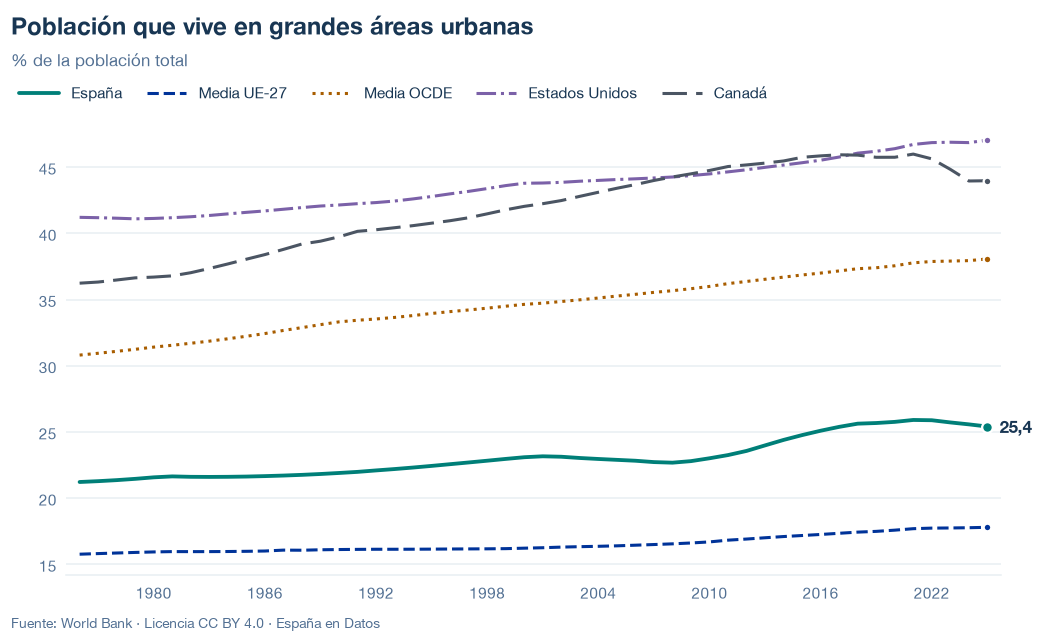

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/poblacion-grandes-ciudades.json y data/poblacion-grandes-ciudades.csv


## 6. Fuentes, notas y licencia

**Fuentes:** organismo, dataset y fecha de consulta (están en `fuentes` del JSON).

**Notas:** rupturas de serie, composición de agregados y datos no disponibles.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.